# Phase 7 — Final training, freeze and one-time held-out evaluation

P1 Full original HGB is the sole primary academic scenario; S1 customer-only HGB sensitivity; B1 Full LR and B2 customer-only LR benchmarks. All 15 predictors remain Provisional. The user explicitly authorized historical academic evaluation under Phase 6B, both stages, and automatic continuation after a saved PASS gate. No deployment or causal claims.

## Google Colab and safe replay

Clone/upload the approved repository with preprocessing.py, both original/cleaned CSVs, saved split, Phase 5A–6B summaries, Phase 6A notebook, tests/test_preprocessing.py and all new models/results/gate files; or mount Drive and set PROJECT_DIR below. Preserve directory structure. Tested Python 3.12, sklearn 1.8.0, pandas 2.2.3, NumPy 2.3.5, scipy 1.17.0, joblib 1.5.3. If packages differ, install pinned versions in a separate setup cell and restart runtime. Standard matplotlib, IPython and threadpoolctl are also needed.

**Default mode is replay:** Run all to verify frozen digests, recreate point metrics/comparison plots from saved predictions and load fixed bootstrap summaries. It does not load joblib objects, fit models, access raw test rows, predict from models or tune using outcomes. The summary is regenerated; frozen model/gate/results files are preserved. The trusted frozen predictions include actual labels for completed reporting.

The original authorized execution set PHASE7_MODE='initial' before running these same cells. Initial mode is only for the first authorized execution with no pre-existing model manifest, gate or test-access marker. It trains 194 development-only fits, writes the mandatory gate, and only on PASS parses test once and evaluates all four models together. It refuses a repeated initial run when exposure/freeze evidence exists. Do not delete those guards to repeat experiments. Fresh reports should use replay. Only load sklearn artifacts from trusted provenance; serialized models require preprocessing.py and matching packages.

## 1. Approved source integrity and authorized development-only loading

Verify source hashes and positional index integrity before data selection. Initial mode parses only saved development rows, restores exact saved order and binds folds to the prior checksum. Whole-file byte hashes are permitted integrity checks, not held-out record inspection. No full-development preprocessing before CV. Pre-test source includes main 9578ebc.


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time,platform,ast,subprocess
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn,scipy,joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV,ParameterGrid
from sklearn.metrics import (average_precision_score,roc_auc_score,accuracy_score,precision_score,recall_score,f1_score,
    confusion_matrix,roc_curve,precision_recall_curve)
from threadpoolctl import threadpool_limits
from IPython.display import display
PROJECT_DIR=Path.cwd() # Set to a repository/Drive directory when necessary.
MODE=globals().get('PHASE7_MODE','replay')
assert MODE in ['initial','replay']
REQUIRED=['preprocessing.py','02_cleaned_dataset.csv','03_split_indices.json','dataset.csv',
 '10_final_model_selection_plan.md','10_feature_availability_matrix.md','09_feature_ablation.ipynb',
 '09_feature_ablation_summary.md','08_imbalance_treatment_summary.md','07_threshold_decision_summary.md','06_nested_cv_targeting_summary.md']
if any(not (PROJECT_DIR/n).is_file() for n in REQUIRED):raise FileNotFoundError('Upload/clone the approved repository; set PROJECT_DIR. Required: '+', '.join(REQUIRED))
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY
MODELS_DIR=PROJECT_DIR/'models';RESULTS_DIR=PROJECT_DIR/'results'
def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
def now():return datetime.now(timezone.utc).isoformat()
def dump_json(p,obj):p.write_text(json.dumps(obj,indent=2,sort_keys=True,allow_nan=False)+'\n')
def event(name,**details):
    row={'event':name,'utc':now(),**details}
    with (RESULTS_DIR/'phase7_events.jsonl').open('a') as f:f.write(json.dumps(row,sort_keys=True)+'\n');f.flush()
    return row

def source_code_digest():
    n=json.loads((PROJECT_DIR/'11_final_training_and_test.ipynb').read_text())
    return hashlib.sha256('\n\n'.join(''.join(c['source']) for c in n['cells'] if c['cell_type']=='code').encode()).hexdigest()
EXPECTED={'dataset.csv':'81fd5eb4b659dddbc704edd90376c32714c3f6a43b887cb686762903bc793f0d',
 '02_cleaned_dataset.csv':'c1a19ca755279a5f22ba22e06b8d5ca22797d9b6351c69fe4cfafd2b47041d49',
 '03_split_indices.json':'397e6e9c66ba3b6b5f6bef6232e00dc392c9ae9d77fdfda28a2d7dc02693596b',
 'preprocessing.py':'3959b4db9a561be5bf7373dfcf82ab85c24a288250e26180599a403b7e551ed8',
 '09_feature_ablation.ipynb':'b753760b1f329cb89882e872a2c594e4606e8db61335ff2fa8212c1f56f9e662'}
source_hashes={n:sha(PROJECT_DIR/n) for n in REQUIRED}
for n,h in EXPECTED.items():assert source_hashes[n]==h,n+' approved digest mismatch'
assert sklearn.__version__=='1.8.0' and pd.__version__=='2.2.3' and np.__version__=='2.3.5'
VERSIONS={'python':platform.python_version(),'sklearn':sklearn.__version__,'pandas':pd.__version__,
 'numpy':np.__version__,'scipy':scipy.__version__,'joblib':joblib.__version__}
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
idx=np.asarray(saved['development_indices'],int);held=np.asarray(saved['held_out_indices'],int)
assert saved['input_sha256']==EXPECTED['02_cleaned_dataset.csv'] and saved['row_count']==41176
assert len(idx)==len(np.unique(idx))==32940 and len(held)==len(np.unique(held))==8236
assert not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
CUSTOMER=['age','job','marital','education','default','housing','loan']
SCENARIOS={'P1':{'role':'Sole Primary','model':'HistGradientBoosting','group':'Full','features':list(FEATURES)},
 'S1':{'role':'Secondary Sensitivity','model':'HistGradientBoosting','group':'Customer Attributes Only','features':CUSTOMER.copy()},
 'B1':{'role':'Secondary Benchmark','model':'LogisticRegression','group':'Full','features':list(FEATURES)},
 'B2':{'role':'Secondary Benchmark','model':'LogisticRegression','group':'Customer Attributes Only','features':CUSTOMER.copy()}}
GRIDS={'HistGradientBoosting':{'classifier__learning_rate':[.05,.1],'classifier__max_iter':[100,200],
 'classifier__max_leaf_nodes':[15,31],'classifier__l2_regularization':[0.,1.]},'LogisticRegression':{'classifier__C':[.1,1.,10.]}}
RULES={'primary_scenario':'P1','scenario_order':list(SCENARIOS),'primary_metric':'AP','secondary_metric':'ROC_AUC',
 'positive_class':1,'classification_threshold':.5,'capacities':[.05,.1,.2],'primary_capacity':.1,
 'contact_counts':[412,824,1648],'ranking_ties':'descending probability; ascending immutable cleaned-row position; bootstrap duplicate draw-occurrence last',
 'bootstrap':{'replicates':2000,'seed':42,'rng':'NumPy default_rng / PCG64','stratified':True,'paired':True,'percentiles':[2.5,97.5],'quantile_method':'linear'},
 'cv':{'n_splits':5,'shuffle':True,'random_state':42},'selection':'maximum mean five-fold positive-predict_proba AP; exact ties first ParameterGrid candidate',
 'class_weight':None,'resampling':None,'calibration':None,'threshold_selection':None,'academic_only':True,'all_15_features':'Provisional',
 'authorization':'User Phase 7 instruction explicitly approves historical academic evaluation of P1/S1/B1/B2, locked capacities/metrics/bootstrap, and automatic Stage 2 continuation after PASS.'}
SOURCE_MAIN='9578ebc'
INITIAL_CODE_SHA=source_code_digest()
FIT_AUDIT=[];PRED_AUDIT=[];WARNING_LOG=[];CONTEXT={};TEST_OPENED=False;FROZEN_MODELS={};selected_rows=[];candidate_rows=[]
if MODE=='initial':
    assert not any((PROJECT_DIR/n).exists() for n in ['models/model_manifest.json','results/test_access_started.json','results/heldout_predictions.csv','12_pre_holdout_release_gate.md']), 'Existing freeze/test evidence: initial mode prohibited; replay frozen results instead.'
    MODELS_DIR.mkdir(exist_ok=True);RESULTS_DIR.mkdir(exist_ok=True)
    event('authorization_recorded',source_main=SOURCE_MAIN,scope=RULES['authorization'],code_sha256=INITIAL_CODE_SHA)
    keep=set(idx.tolist())
    dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda line:line>0 and line-1 not in keep)
    assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
    dev.index=np.sort(idx);dev=dev.loc[idx].copy();snapshot=dev.copy(deep=True)
    assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
    assert np.isfinite(dev[NUMERICAL+RECENCY].to_numpy()).all()
    assert dev.recency_available.isin([0,1]).all() and dev.recency_days.between(0,27).all()
    assert dev.loc[dev.recency_available.eq(0),'recency_days'].eq(0).all()
    X=dev[FEATURES].copy();y=dev.y.copy();DEV_KEY=frozenset(idx)
    folds=list(make_cv().split(X,y))
    fold_hash=hashlib.sha256(b''.join(idx[b].astype('<i8').tobytes() for _,b in folds)).hexdigest()
    assert fold_hash=='6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4'
    for (a,b),(aa,bb) in zip(folds,make_cv().split(X,y)):
        np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
    CONTEXT.update(fit_keys={frozenset(X.iloc[a].index) for a,b in folds},val_keys={frozenset(X.iloc[b].index) for a,b in folds})
    dump_json(MODELS_DIR/'phase7_protocol.json',{'source_main':SOURCE_MAIN,'sources':source_hashes,'code_sha256':INITIAL_CODE_SHA,'scenarios':SCENARIOS,'grids':GRIDS,'rules':RULES,'versions':VERSIONS,'fold_sha256':fold_hash})
    print('Authorized initial run: development only loaded; exact fold/hash integrity PASS. No held-out record parsed.')
else:
    assert (RESULTS_DIR/'evaluation_complete.json').is_file(),'Replay requires the completed frozen results/ directory; it never triggers training or test access.'
    print('Replay mode: no model fitting, raw test parsing, model prediction or test-informed tuning. Load frozen results only.')



Authorized initial run: development only loaded; exact fold/hash integrity PASS. No held-out record parsed.


## 2. Fresh approved pipelines, subset equivalence and pre-test audits

Extract only the approved subset_preprocessor function from the digest-verified Phase 6A notebook. Full output/statistics must equal the unchanged factory; customer-only removes the complete recency transformer and other excluded columns. OHE is fitting-only; LR StandardScaler uses fitting rows and ConditionalRecencyScaler uses only available fitting recency. HGB remains unscaled with numeric indicators, categorical_features=None and early_stopping=False.

The audit subclass enforces exact development fitting/validation partitions and returns the approved representations unchanged. Metrics and deterministic capacity/tie rules are defined and checked using synthetic data before test access. Four approved preprocessing unit tests run before model training. Default LR in sklearn 1.8 uses l1_ratio=0 for approved L2; no deprecated-parameter change is introduced.


In [2]:
GROUPS={'Full':list(FEATURES),'Customer Attributes Only':CUSTOMER.copy()};HISTORY=['previous','recency_available','recency_days']
# Reuse the exact approved Phase 6A adapter definition (source extraction, no notebook execution).
nb6=json.loads((PROJECT_DIR/'09_feature_ablation.ipynb').read_text())
code6='\n'.join(''.join(c['source']) for c in nb6['cells'] if c['cell_type']=='code');tree=ast.parse(code6)
fn=next(n for n in tree.body if isinstance(n,ast.FunctionDef) and n.name=='subset_preprocessor')
exec(compile(ast.Module(body=[fn],type_ignores=[]),'<approved Phase 6A adapter>','exec'))

def signature(pre):
    ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical'];num=ct.named_transformers_['numerical'];rec=ct.named_transformers_.get('recency')
    z={'categories':[v.tolist() for v in enc.categories_],'feature_names':pre.get_feature_names_out().tolist()}
    if hasattr(num,'mean_'):z['numeric']={'mean':num.mean_.tolist(),'variance':num.var_.tolist(),'scale':num.scale_.tolist(),'n_samples':np.asarray(num.n_samples_seen_).tolist()}
    if hasattr(rec,'mean_'):z['recency']={'mean':rec.mean_,'variance':rec.var_,'scale':rec.scale_,'available_samples':rec.n_available_}
    return z

def representation_check(pre,data,model,features,check_training=False):
    ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical'];nums=[c for c in NUMERICAL if c in features];rec=ct.named_transformers_.get('recency')
    assert data.columns.tolist()==features
    assert enc.drop is None and enc.handle_unknown=='ignore' and not enc.sparse_output
    assert set(c for name,t,cs in ct.transformers if name!='remainder' for c in cs)==set(features)
    if check_training:
        for c,categories in zip(CATEGORICAL,enc.categories_):np.testing.assert_array_equal(categories,np.sort(data[c].unique()))
    if model=='LogisticRegression':
        num=ct.named_transformers_['numerical']
        if check_training:
            np.testing.assert_allclose(num.mean_,data[nums].mean(),rtol=1e-12,atol=1e-12)
            np.testing.assert_allclose(num.var_,data[nums].var(ddof=0),rtol=1e-12,atol=1e-12)
            sd=np.sqrt(data[nums].var(ddof=0).to_numpy());sd[sd==0]=1
            np.testing.assert_allclose(num.scale_,sd,rtol=1e-12,atol=1e-12);assert np.all(np.asarray(num.n_samples_seen_)==len(data))
            if rec is not None:
                obs=data.loc[data.recency_available.eq(1),'recency_days'].to_numpy();mean=float(obs.mean()) if len(obs) else 0.;var=float(obs.var(ddof=0)) if len(obs) else 0.
                np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[mean,var,np.sqrt(var) if var>0 else 1.],rtol=1e-12);assert rec.n_available_==len(obs)
    else:assert not hasattr(ct.named_transformers_['numerical'],'mean_') and not hasattr(rec,'mean_')
    before=signature(pre);z=pre.transform(data);assert signature(pre)==before
    assert np.isfinite(z).all() and z.shape[1]==len(pre.get_feature_names_out())
    tail=len(nums)+(2 if rec is not None else 0);assert np.isin(z[:,:-tail],[0.,1.]).all()
    if rec is not None:
        assert features==FEATURES;np.testing.assert_array_equal(z[:,-1],data.recency_available)
        assert (z[data.recency_available.eq(0).to_numpy(),-2]==0).all()
        if hasattr(rec,'mean_'):
            avail=data.recency_available.eq(1).to_numpy();np.testing.assert_allclose(z[avail,-2],(data.loc[avail,'recency_days']-rec.mean_)/rec.scale_)
    else:
        assert features==CUSTOMER and 'recency' not in [t[0] for t in ct.transformers_] and not any('recency' in str(n) for n in pre.get_feature_names_out())
    if model=='HistGradientBoosting':np.testing.assert_array_equal(z[:,-tail:],data[nums+(RECENCY if rec is not None else [])].to_numpy())
    return z

class AuditedPipeline(Pipeline):
    def fit(self,data,target=None,**params):
        assert MODE=='initial' and not TEST_OPENED
        key=frozenset(data.index);spec=SCENARIOS[CONTEXT['scenario']]
        assert key in CONTEXT['fit_keys'] or key==DEV_KEY
        assert not key.intersection(held) and np.array_equal(data.index,target.index)
        assert data.columns.tolist()==spec['features']
        assert not hasattr(self.named_steps['preprocessing'].named_steps['preprocessor'],'transformers_')
        with warnings.catch_warnings(record=True) as ws,threadpool_limits(limits=1):
            warnings.simplefilter('always');out=super().fit(data,target,**params)
        for w in ws:WARNING_LOG.append({'scenario':CONTEXT['scenario'],'category':w.category.__name__,'message':str(w.message)})
        if ws:raise RuntimeError('Unexpected model/preprocessing warning: '+str(WARNING_LOG))
        pre=self.named_steps['preprocessing'];representation_check(pre,data,spec['model'],spec['features'],check_training=True)
        clf=self.named_steps['classifier'];np.testing.assert_array_equal(clf.classes_,[0,1]);assert clf.class_weight is None and clf.random_state==42
        if spec['model']=='HistGradientBoosting':
            assert clf.categorical_features is None and clf.early_stopping is False and clf.n_iter_==clf.max_iter
            assert clf.is_categorical_ is None or not np.any(clf.is_categorical_)
        else:
            # sklearn 1.8 default l1_ratio=0 implements the approved L2 configuration;
            # explicitly setting deprecated penalty='l2' would only add a warning.
            assert clf.solver=='lbfgs' and clf.max_iter==1000 and clf.l1_ratio==0 and clf.penalty in ['deprecated','l2']
            assert np.isfinite(clf.coef_).all() and np.isfinite(clf.intercept_).all()
        self._fit_key=key
        FIT_AUDIT.append({'scenario':CONTEXT['scenario'],'role':'final_development_refit' if key==DEV_KEY else 'cv_training',
            'rows':len(data),'row_sha256':hashlib.sha256(data.index.to_numpy(dtype='<i8').tobytes()).hexdigest(),
            'statistics':signature(pre),'status':'PASS'})
        return out
    def predict_proba(self,data,**params):
        assert not TEST_OPENED
        key=frozenset(data.index);spec=SCENARIOS[CONTEXT['scenario']]
        if CONTEXT['prediction_role']=='cv_validation':assert key in CONTEXT['val_keys'] and not key.intersection(self._fit_key)
        else:assert CONTEXT['prediction_role']=='development_fixture' and self._fit_key==DEV_KEY and key.issubset(DEV_KEY)
        assert not key.intersection(held)
        pre=self.named_steps['preprocessing'];before=signature(pre);representation_check(pre,data,spec['model'],spec['features'])
        with threadpool_limits(limits=1):prob=super().predict_proba(data,**params)
        assert signature(pre)==before and np.isfinite(prob).all() and ((prob>=0)&(prob<=1)).all()
        PRED_AUDIT.append({'scenario':CONTEXT['scenario'],'role':CONTEXT['prediction_role'],'rows':len(data),'status':'PASS'})
        return prob

def factory(scenario):
    spec=SCENARIOS[scenario]
    if spec['model']=='HistGradientBoosting':clf=HistGradientBoostingClassifier(early_stopping=False,categorical_features=None,class_weight=None,random_state=42)
    else:clf=LogisticRegression(solver='lbfgs',max_iter=1000,random_state=42,class_weight=None)
    return AuditedPipeline([('preprocessing',subset_preprocessor(spec['model'],spec['group'])),('classifier',clf)])

def scorer(est,data,target):
    assert CONTEXT['prediction_role']=='cv_validation' and np.array_equal(data.index,target.index)
    p=est.predict_proba(data)[:,list(est.classes_).index(1)]
    return {'AP':average_precision_score(target,p)}

# Metric definitions frozen before test access, tested on synthetic data only.
def metrics(actual,prob):
    a=np.asarray(actual);p=np.asarray(prob);pred=(p>=.5).astype(int);tn,fp,fn,tp=map(int,confusion_matrix(a,pred,labels=[0,1]).ravel())
    return {'AP':float(average_precision_score(a,p)),'ROC_AUC':float(roc_auc_score(a,p)),
        'Accuracy':float(accuracy_score(a,pred)),'Precision':float(precision_score(a,pred,zero_division=0)),
        'Recall':float(recall_score(a,pred,zero_division=0)),'F1':float(f1_score(a,pred,zero_division=0)),
        'predicted_positive_count':int(pred.sum()),'predicted_positive_fraction':float(pred.mean()),'TN':tn,'FP':fp,'FN':fn,'TP':tp}

def targeting(actual,prob,positions,fraction,draw_occurrence=None):
    a=np.asarray(actual);p=np.asarray(prob);positions=np.asarray(positions);k=int(np.ceil(len(a)*fraction))
    occurrence=np.arange(len(a)) if draw_occurrence is None else np.asarray(draw_occurrence)
    order=np.lexsort((occurrence,positions,-p));cap=int(a[order[:k]].sum());precision=cap/k;total=int(a.sum())
    return {'contacts':k,'captured_subscribers':cap,'Precision_at_K':precision,'Recall_at_K':cap/total,'Lift_at_K':precision/(total/len(a))}

def mdtable(frame):
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |','| '+' | '.join(['---']*len(frame.columns))+' |']+['| '+' | '.join(fmt(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None)])

if MODE=='initial':
    a=np.array([1,0,1,0]);p=np.array([.2,.2,.8,.1]);pos=np.array([5,1,9,2])
    assert targeting(a,p,pos,.5)['captured_subscribers']==1
    assert metrics(a,p)['TP']==1 and metrics(a,p)['FN']==1
    # Duplicate-draw ties retain immutable row and occurrence order, without labels.
    assert targeting([1,0,1],[.5,.5,.5],[9,2,9],1/3,[0,1,2])['captured_subscribers']==0
    fixture_train=X.iloc[folds[0][0][:300]];fixture_val=X.iloc[folds[0][0][300:400]].copy();fixture_val.iloc[0,fixture_val.columns.get_loc('job')]='__unseen_fixture__'
    fixture_checks=[]
    for model in ['HistGradientBoosting','LogisticRegression']:
        name='decision_tree' if model=='HistGradientBoosting' else 'logistic_regression'
        original=make_preprocessor(name).fit(fixture_train);adapted=subset_preprocessor(model,'Full').fit(fixture_train)
        assert signature(original)==signature(adapted)
        np.testing.assert_array_equal(original.transform(fixture_val),adapted.transform(fixture_val))
        for group,features in GROUPS.items():
            pre=subset_preprocessor(model,group).fit(fixture_train[features]);representation_check(pre,fixture_val[features],model,features)
            enc=pre.named_steps['preprocessor'].named_transformers_['categorical'];assert '__unseen_fixture__' not in enc.categories_[0]
            fixture_checks.append({'model':model,'group':group,'status':'PASS'})
    for sid in SCENARIOS:clone(factory(sid))
    result=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=PROJECT_DIR,capture_output=True,text=True)
    assert result.returncode==0 and 'Ran 4 tests' in result.stderr,result.stdout+result.stderr
    unit_log=result.stdout+result.stderr
    (RESULTS_DIR/'preprocessing_tests.txt').write_text(unit_log)
    dump_json(RESULTS_DIR/'development_fixture_checks.json',fixture_checks)
    print('Pre-training: exact adapter equivalence, subset removal, synthetic metric/tie checks, four approved unit tests PASS.')



Pre-training: exact adapter equivalence, subset removal, synthetic metric/tie checks, four approved unit tests PASS.


## 3. Final development-only search, selection and model freeze

Each scenario independently uses StratifiedKFold(5,shuffle=True,random_state=42), exact approved grids, positive-predict_proba AP scorer, refit='AP', n_jobs=1 and error_score='raise'. Highest unrounded mean AP wins; exact ties take first ParameterGrid candidate. Budget: 190 candidate-fold fits plus four final development-only refits. CV scores here are selection estimates.

Freeze complete fitted plain sklearn Pipelines using the same learned steps, without refitting. Save four trusted artifacts and a manifest of selected parameters, complete classifier configuration, ordered inputs, preprocessing statistics/classes, versions, seeds, source/model hashes and evaluation rules. Reload each locally created artifact and verify bit-identical probabilities on development-only fixture rows. No test reading yet.


In [3]:
if MODE=='initial':
    training_started=time.perf_counter();training_metadata={}
    for sid,spec in SCENARIOS.items():
        assert not TEST_OPENED;CONTEXT.update(scenario=sid,prediction_role='cv_validation')
        before=len(FIT_AUDIT);before_p=len(PRED_AUDIT);t=time.perf_counter()
        search=GridSearchCV(factory(sid),GRIDS[spec['model']],scoring=scorer,refit='AP',cv=folds,n_jobs=1,error_score='raise',return_train_score=False)
        search.fit(X[spec['features']],y)
        params=list(ParameterGrid(GRIDS[spec['model']]));n=len(params)
        assert search.cv_results_['params']==params and len(FIT_AUDIT)-before==5*n+1 and len(PRED_AUDIT)-before_p==5*n
        scores=np.asarray(search.cv_results_['mean_test_AP']);assert np.isfinite(scores).all()
        expected=int(np.argmax(scores));assert search.best_index_==expected and search.best_params_==params[expected]
        for i,par in enumerate(params):
            vals=[float(search.cv_results_[f'split{fold}_test_AP'][i]) for fold in range(5)]
            candidate_rows.append({'scenario':sid,'candidate_order_zero_based':i,'parameters':json.dumps(par,sort_keys=True),
                **{f'fold_{j+1}_AP':v for j,v in enumerate(vals)},'mean_AP_selection_only':float(np.mean(vals)),
                'sample_SD_AP':float(np.std(vals,ddof=1)),'selected':i==expected})
        CONTEXT['prediction_role']='development_fixture';fixture=X.iloc[:256][spec['features']]
        audited=search.best_estimator_;expected_prob=audited.predict_proba(fixture)
        # Serialize a plain sklearn Pipeline with the exact already-fitted steps.
        # Audit wrapper is not a learned transformer and is not needed for loading.
        frozen=Pipeline(steps=audited.steps)
        with threadpool_limits(limits=1):np.testing.assert_array_equal(frozen.predict_proba(fixture),expected_prob)
        path=MODELS_DIR/(sid+'_pipeline.joblib');joblib.dump(frozen,path,compress=3)
        loaded=joblib.load(path) # Trusted artifact created above in this authorized run.
        with threadpool_limits(limits=1):np.testing.assert_array_equal(loaded.predict_proba(fixture),expected_prob)
        assert signature(loaded.named_steps['preprocessing'])==signature(frozen.named_steps['preprocessing'])
        FROZEN_MODELS[sid]=loaded
        metadata={'scenario':sid,**spec,'selected_parameters':search.best_params_,'classifier_configuration':loaded.named_steps['classifier'].get_params(deep=False),
            'classes':loaded.classes_.tolist(),'preprocessing_statistics':signature(loaded.named_steps['preprocessing']),
            'preprocessing_configuration':{'factory':'logistic_regression' if spec['model']=='LogisticRegression' else 'decision_tree',
                'adapter':'exact Phase 6A subset_preprocessor','ohe':'full, drop=None, handle_unknown=ignore, dense float64',
                'numeric_scaling':'training-only StandardScaler' if spec['model']=='LogisticRegression' else 'unscaled',
                'recency':'approved conditional scaler' if sid=='B1' else ('unscaled recency pair' if sid=='P1' else 'component completely removed')},
            'random_state':42,'training_rows':32940,'training_sha256':source_hashes['02_cleaned_dataset.csv'],
            'preprocessing_sha256':source_hashes['preprocessing.py'],'artifact':str(path.relative_to(PROJECT_DIR)),'artifact_sha256':sha(path),
            'development_fixture_rows':256,'reload_identical_probabilities':True,'mean_CV_AP_selection_only':float(search.best_score_),
            'seconds':time.perf_counter()-t}
        training_metadata[sid]=metadata;selected_rows.append({'scenario':sid,'role':spec['role'],'group':spec['group'],
            'selected_parameters':json.dumps(search.best_params_,sort_keys=True),'CV_AP_selection_only':float(search.best_score_),'seconds':metadata['seconds']})
        event('scenario_frozen',scenario=sid,artifact_sha256=metadata['artifact_sha256'],development_only=True)
        print(sid,'frozen; selected',search.best_params_,'CV selection AP',f'{search.best_score_:.6f}','seconds',f'{metadata["seconds"]:.1f}',flush=True)
    assert len(FIT_AUDIT)==194 and sum(a['role']=='cv_training' for a in FIT_AUDIT)==190
    assert sum(a['role']=='final_development_refit' for a in FIT_AUDIT)==4
    assert sum(a['role']=='cv_validation' for a in PRED_AUDIT)==190
    assert len(candidate_rows)==38 and not WARNING_LOG
    assert list(FROZEN_MODELS)==list(SCENARIOS)
    manifest={'source_main':SOURCE_MAIN,'frozen_at_utc':now(),'versions':VERSIONS,'sources':source_hashes,'execution_code_sha256':INITIAL_CODE_SHA,
        'training_row_count':32940,'held_out_row_count_not_loaded':8236,'fold_sha256':fold_hash,'scenario_order':list(SCENARIOS),
        'rules':RULES,'grids':GRIDS,'scenarios':training_metadata,'fit_counts':{'CV':190,'final_development_refits':4,'total':194},
        'unit_tests':'4 passed','model_warnings':WARNING_LOG,'training_seconds':time.perf_counter()-training_started}
    dump_json(MODELS_DIR/'model_manifest.json',manifest)
    dump_json(RESULTS_DIR/'development_fit_audit.json',FIT_AUDIT);dump_json(RESULTS_DIR/'development_prediction_audit.json',PRED_AUDIT)
    pd.DataFrame(candidate_rows).to_csv(RESULTS_DIR/'development_cv_candidates.csv',index=False,float_format='%.17g')
    pd.DataFrame(selected_rows).to_csv(RESULTS_DIR/'final_selected_parameters.csv',index=False,float_format='%.17g')
else:
    manifest=json.loads((MODELS_DIR/'model_manifest.json').read_text());assert manifest['scenario_order']==list(SCENARIOS) and manifest['rules']==RULES
    for sid,meta in manifest['scenarios'].items():assert sha(PROJECT_DIR/meta['artifact'])==meta['artifact_sha256']
    print('Replay: manifest/model byte digests verified; no joblib loading, fitting or model predictions.')
display(pd.read_csv(RESULTS_DIR/'final_selected_parameters.csv'))



P1 frozen; selected {'classifier__l2_regularization': 1.0, 'classifier__learning_rate': 0.05, 'classifier__max_iter': 200, 'classifier__max_leaf_nodes': 15} CV selection AP 0.448069 seconds 100.6
S1 frozen; selected {'classifier__l2_regularization': 0.0, 'classifier__learning_rate': 0.05, 'classifier__max_iter': 100, 'classifier__max_leaf_nodes': 15} CV selection AP 0.233785 seconds 85.4
B1 frozen; selected {'classifier__C': 0.1} CV selection AP 0.422429 seconds 2.1
B2 frozen; selected {'classifier__C': 0.1} CV selection AP 0.202251 seconds 1.7


scenario,role,group,selected_parameters,CV_AP_selection_only,seconds
P1,Sole Primary,Full,"{""classifier__l2_regularization"": 1.0, ""classifier__learning_rate"": 0.05, ""classifier__max_iter"": 200, ""classifier__max_leaf_nodes"": 15}",0.448069,100.591032
S1,Secondary Sensitivity,Customer Attributes Only,"{""classifier__l2_regularization"": 0.0, ""classifier__learning_rate"": 0.05, ""classifier__max_iter"": 100, ""classifier__max_leaf_nodes"": 15}",0.233785,85.355146
B1,Secondary Benchmark,Full,"{""classifier__C"": 0.1}",0.422429,2.079500
B2,Secondary Benchmark,Customer Attributes Only,"{""classifier__C"": 0.1}",0.202251,1.738402


## 4. Mandatory pre-holdout release gate

All fourteen checks must pass: fitting isolation, schemas, recency removal/behavior, finite outputs/class mapping, trusted reloads, source/code/model digests, fixed roster/policies/bootstrap, warning-free execution and explicit academic authorization. Save 12_pre_holdout_release_gate.md and release_gate.json **before** any held-out parser call. Failure stops execution and prohibits test access. A PASS permits automatic continuation under the user's existing approval. The gate is a technical check, not feature-timing verification.


In [4]:
if MODE=='initial':
    checks=[]
    def gate_check(name,condition):
        checks.append({'requirement':name,'status':'PASS' if bool(condition) else 'FAIL'})
        if not condition:raise RuntimeError('Release gate failed: '+name)
    gate_check('194 development-only fits / 190 CV +4 final refits',manifest['fit_counts']=={'CV':190,'final_development_refits':4,'total':194})
    gate_check('Exact four scenarios/roles and fixed parameter choices recorded',list(manifest['scenarios'])==list(SCENARIOS))
    gate_check('Exact ordered full/customer input schemas',all(v['features']==SCENARIOS[sid]['features'] for sid,v in manifest['scenarios'].items()))
    gate_check('Fitting-only OHE/ordinary/conditional statistics audited',all(v['status']=='PASS' for v in FIT_AUDIT))
    gate_check('Approved conditional recency, placeholder and unscaled indicator behavior',all(v['status']=='PASS' for v in fixture_checks))
    gate_check('Customer-only recency components fully removed',all('recency' not in FROZEN_MODELS[sid].named_steps['preprocessing'].named_steps['preprocessor'].named_transformers_ for sid in ['S1','B2']))
    gate_check('Finite probabilities and correct [0,1] mapping',all(v['classes']==[0,1] and v['reload_identical_probabilities'] for v in manifest['scenarios'].values()))
    gate_check('Four trusted serialized pipelines reload identically',all(v['reload_identical_probabilities'] and sha(PROJECT_DIR/v['artifact'])==v['artifact_sha256'] for v in manifest['scenarios'].values()))
    gate_check('All sources, split, code and model digests unchanged',all(sha(PROJECT_DIR/n)==h for n,h in source_hashes.items()) and source_code_digest()==INITIAL_CODE_SHA)
    gate_check('Roster P1 sole primary / S1 B1 B2 secondary unchanged',manifest['scenario_order']==['P1','S1','B1','B2'] and RULES['primary_scenario']=='P1')
    gate_check('Metrics/capacities/ties/2,000 paired-stratified bootstrap frozen',manifest['rules']==RULES and manifest['grids']==GRIDS)
    gate_check('No unexpected warnings/errors and all four preprocessing tests pass',not WARNING_LOG and 'Ran 4 tests' in unit_log and '\nOK' in unit_log)
    gate_check('Explicit user authorization and academic-only interpretation recorded',RULES['academic_only'] and RULES['all_15_features']=='Provisional' and 'User Phase 7' in RULES['authorization'])
    gate_check('No test parse/profile/transform/prediction/evaluation before this gate',not TEST_OPENED and not (RESULTS_DIR/'test_access_started.json').exists())
    pd.testing.assert_frame_equal(dev,snapshot,check_exact=True)
    release={'status':'PASS','saved_at_utc':now(),'checks':checks,'manifest_sha256':sha(MODELS_DIR/'model_manifest.json'),
        'protocol_sha256':sha(MODELS_DIR/'phase7_protocol.json'),'execution_code_sha256':INITIAL_CODE_SHA,'test_accesses_before_gate':0}
    gate_text='# Phase 7 — Mandatory pre-holdout technical release gate\n\n**PASS — All requirements satisfied.**\n\n'
    gate_text+='Saved UTC: '+release['saved_at_utc']+'\n\nAuthority: '+RULES['authorization']+' All 15 predictors remain Provisional; this is conditional historical academic evaluation, not deployment validation.\n\n'
    gate_text+=mdtable(pd.DataFrame(checks))+'\n\nFrozen selected configurations:\n\n'+mdtable(pd.DataFrame(selected_rows))+'\n\n'
    gate_text+='Source main: `'+SOURCE_MAIN+'`. Full data/split/source hashes, pipeline statistics, ordered schemas, versions, full classifier configurations and artifact hashes are in models/model_manifest.json and models/phase7_protocol.json.\n\n'
    gate_text+='Manifest SHA-256: `'+release['manifest_sha256']+'`. Protocol SHA-256: `'+release['protocol_sha256']+'`. Execution code SHA-256: `'+INITIAL_CODE_SHA+'`.\n\n'
    gate_text+='No test records or performance have been accessed at the time this document is saved. Training-only category/scaler/recency audits and original/full-adapter equivalence passed. Four models reloaded with bit-identical development-fixture probabilities; no unexpected warnings. Metric/targeting synthetic checks and four approved preprocessing unit tests passed.\n\n'
    gate_text+='Locked positive class 1; threshold >=0.50; AP primary, ROC-AUC secondary; top 10% (824) primary illustrative business capacity and top 5% (412)/20% (1648) secondary. Ties: descending score then cleaned-row position, bootstrap duplicate occurrence last. Bootstrap: 2,000 paired stratified within-class replacement draws, NumPy default_rng(42), original class counts retained, no fitting/calibration; descriptive 2.5/97.5 percentile intervals.\n\n'
    gate_text+='This PASS authorizes continuation to exactly one batch under the existing user approval. It is a technical isolation gate, not verification of feature timing, customer independence, causality or prospective deployment. Any mandatory failure prohibits test access. This document is preserved unchanged after test opening.\n'
    (PROJECT_DIR/'12_pre_holdout_release_gate.md').write_text(gate_text)
    release['gate_document_sha256']=sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')
    dump_json(RESULTS_DIR/'release_gate.json',release)
    gate_digest=release['gate_document_sha256']
    event('release_gate_saved',status='PASS',gate_sha256=gate_digest,manifest_sha256=release['manifest_sha256'])
    assert (PROJECT_DIR/'12_pre_holdout_release_gate.md').is_file() and sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')==gate_digest
    print('PASS — All requirements satisfied. Release-gate document is saved BEFORE any held-out parser invocation.',flush=True)
else:
    release=json.loads((RESULTS_DIR/'release_gate.json').read_text());assert release['status']=='PASS'
    assert sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')==release['gate_document_sha256']
    print('Replay: preserved pre-test PASS gate digest verified; no new test opening.')



PASS — All requirements satisfied. Release-gate document is saved BEFORE any held-out parser invocation.


## 5. One-time four-scenario evaluation batch

Only initial mode with a saved PASS gate can create the irreversible access marker, parse the exact held-out partition once and call each frozen pipeline's predict_proba once. Generate and freeze all four vectors before computing any metric; P1 remains primary regardless of observed ordering. No fit/fit_transform, encoding/scaling updates, calibration, threshold tuning, dropped rows or extra scenarios. Replay loads the immutable prediction CSV only.

Report AP, ROC-AUC, fixed >=.50 metrics/counts/confusion entries and predefined capacities 412/824/1648. Top 10% is illustrative primary business reporting, not a known bank budget. Ties use score then immutable cleaned-row position, never outcome. Historical capture is not causal call uplift.


In [5]:
if MODE=='initial':
    assert release['status']=='PASS' and not TEST_OPENED and not (RESULTS_DIR/'test_access_started.json').exists()
    assert sha(MODELS_DIR/'model_manifest.json')==release['manifest_sha256'] and source_code_digest()==release['execution_code_sha256']
    assert sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')==release['gate_document_sha256']
    for sid,meta in manifest['scenarios'].items():assert sha(PROJECT_DIR/meta['artifact'])==meta['artifact_sha256']
    # Persist the irreversible access marker BEFORE starting the held-out CSV parser.
    access={'utc':now(),'batch':'phase7_one_time_four_scenario_batch','gate_sha256':release['gate_document_sha256'],
        'gate_saved_at_utc':release['saved_at_utc'],'scenario_order':list(SCENARIOS),'held_out_parser_invocations':1}
    dump_json(RESULTS_DIR/'test_access_started.json',access);event('held_out_access_started',gate_sha256=release['gate_document_sha256'])
    TEST_OPENED=True;keep_test=set(held.tolist())
    test=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda line:line>0 and line-1 not in keep_test)
    assert test.shape==(8236,16) and test.columns.tolist()==FEATURES+['y']
    test.index=np.sort(held);test=test.loc[held].copy()
    assert test.y.isin([0,1]).all() and not test.isna().any().any()
    assert test.y.nunique()==2,'Unexpected one-class test cohort: stop; do not invent undefined metrics.'
    frozen_predictions=pd.DataFrame({'cleaned_row_position':held,'y':test.y.to_numpy()})
    test_prediction_calls={};prediction_warnings=[]
    # Generate all four probability vectors before calculating/displaying any metric.
    for sid in SCENARIOS:
        spec=SCENARIOS[sid];frozen=FROZEN_MODELS[sid];pre=frozen.named_steps['preprocessing'];before=signature(pre)
        with warnings.catch_warnings(record=True) as ws,threadpool_limits(limits=1):
            warnings.simplefilter('always');proba=frozen.predict_proba(test[spec['features']])
        prediction_warnings.extend({'scenario':sid,'message':str(w.message),'category':w.category.__name__} for w in ws)
        assert not ws,'Unexpected test-prediction warning; no test-informed correction.'
        assert signature(pre)==before and proba.shape==(8236,2) and np.isfinite(proba).all() and ((proba>=0)&(proba<=1)).all()
        np.testing.assert_array_equal(frozen.classes_,[0,1]);frozen_predictions[sid]=proba[:,list(frozen.classes_).index(1)]
        test_prediction_calls[sid]=1
    assert test_prediction_calls==dict.fromkeys(SCENARIOS,1) and len(FIT_AUDIT)==194
    # Round-trip exact probabilities; records are retained once for report-only replay.
    frozen_predictions.to_csv(RESULTS_DIR/'heldout_predictions.csv',index=False,float_format='%.17g')
    persisted=pd.read_csv(RESULTS_DIR/'heldout_predictions.csv',float_precision='round_trip')
    pd.testing.assert_frame_equal(persisted,frozen_predictions,check_exact=True)
    dump_json(RESULTS_DIR/'test_prediction_audit.json',{'gate_preceded_parse':True,'test_parser_invocations':1,
        'predict_proba_calls':test_prediction_calls,'no_test_fit_calls':True,'model_warnings':prediction_warnings,
        'all_four_vectors_completed_before_any_score':True,'predictions_sha256':sha(RESULTS_DIR/'heldout_predictions.csv')})
    event('all_four_probability_vectors_frozen',prediction_sha256=sha(RESULTS_DIR/'heldout_predictions.csv'),calls=test_prediction_calls)
    del test
else:
    frozen_predictions=pd.read_csv(RESULTS_DIR/'heldout_predictions.csv',float_precision='round_trip')
    done=json.loads((RESULTS_DIR/'evaluation_complete.json').read_text())
    for name,h in done['result_hashes'].items():assert sha(PROJECT_DIR/name)==h,name+' frozen result digest mismatch'
# All score/report operations below use frozen predictions, not model refitting/prediction.
np.testing.assert_array_equal(frozen_predictions.cleaned_row_position,held)
actual=frozen_predictions.y.to_numpy();positions=frozen_predictions.cleaned_row_position.to_numpy()
point_rows=[];business_rows=[]
for sid,spec in SCENARIOS.items():
    point_rows.append({'scenario':sid,'role':spec['role'],**metrics(actual,frozen_predictions[sid].to_numpy())})
    for fraction in RULES['capacities']:business_rows.append({'scenario':sid,'fraction':fraction,
        'capacity_role':'Primary illustrative' if fraction==.1 else 'Secondary',**targeting(actual,frozen_predictions[sid],positions,fraction)})
point=pd.DataFrame(point_rows);business=pd.DataFrame(business_rows)
assert business.groupby('fraction').contacts.nunique().eq(1).all()
assert business.groupby('fraction').contacts.first().tolist()==[412,824,1648]
if MODE=='initial':
    point.to_csv(RESULTS_DIR/'heldout_metrics.csv',index=False,float_format='%.17g')
    business.to_csv(RESULTS_DIR/'heldout_topk.csv',index=False,float_format='%.17g')
    event('predeclared_batch_metrics_saved',scenario_count=4,primary='P1')
print('One-time batch complete; fixed test prevalence:',float(actual.mean()))
display(point);display(business)



One-time batch complete; fixed test prevalence: 0.11267605633802817


scenario,role,AP,ROC_AUC,Accuracy,Precision,Recall,F1,predicted_positive_count,predicted_positive_fraction,TN,FP,FN,TP
P1,Sole Primary,0.451334,0.807608,0.896552,0.619497,0.212284,0.316212,318,0.038611,7187,121,731,197
S1,Secondary Sensitivity,0.230981,0.669764,0.887688,0.615385,0.008621,0.017003,13,0.001578,7303,5,920,8
B1,Secondary Benchmark,0.431032,0.777331,0.898009,0.676000,0.182112,0.286927,250,0.030355,7227,81,759,169
B2,Secondary Benchmark,0.200407,0.648536,0.887324,0.000000,0.000000,0.000000,0,0.000000,7308,0,928,0


scenario,fraction,capacity_role,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
P1,0.05,Secondary,412,248,0.601942,0.267241,5.342233
P1,0.10,Primary illustrative,824,412,0.500000,0.443966,4.437500
P1,0.20,Secondary,1648,610,0.370146,0.657328,3.285042
S1,0.05,Secondary,412,156,0.378641,0.168103,3.360437
S1,0.10,Primary illustrative,824,224,0.271845,0.241379,2.412621
S1,0.20,Secondary,1648,338,0.205097,0.364224,1.820237
B1,0.05,Secondary,412,240,0.582524,0.258621,5.169903
B1,0.10,Primary illustrative,824,396,0.480583,0.426724,4.265170
B1,0.20,Secondary,1648,586,0.355583,0.631466,3.155795
B2,0.05,Secondary,412,123,0.298544,0.132543,2.649575


## 6. Frozen paired stratified uncertainty procedure

Initial execution uses exactly 2,000 default_rng(42) within-class replacement draws, keeping class counts and sharing each draw across all four scenarios. Recompute AP/ROC-AUC, .50 metrics and every Top-K measure; no model/transform/predict call. Bootstrap duplicate ties use original row position then draw occurrence. Save replicate metrics, draw hashes and descriptive percentile intervals. Replay loads these frozen outputs, not a new experiment.

Intervals condition on fitted models/class balance; no claim they cover model selection, customer/time overlap, future shifts, feature timing or causal effects. No significance-winner or primary-scenario reselection.


In [6]:
if MODE=='initial':
    bootstrap_started=time.perf_counter();rng=np.random.default_rng(42);class_positions=[np.flatnonzero(actual==c) for c in [0,1]]
    boot_rows=[];draw_rows=[]
    for replicate in range(2000):
        draw=np.concatenate([rng.choice(c,size=len(c),replace=True) for c in class_positions])
        a=actual[draw];rowpos=positions[draw];occ=np.arange(len(draw))
        assert len(draw)==8236 and int(a.sum())==int(actual.sum())
        draw_rows.append({'replicate':replicate,'draw_sha256':hashlib.sha256(draw.astype('<i8').tobytes()).hexdigest()})
        for sid in SCENARIOS:
            p=frozen_predictions[sid].to_numpy()[draw]
            record={'replicate':replicate,'scenario':sid,**metrics(a,p)}
            for fraction in RULES['capacities']:
                tk=targeting(a,p,rowpos,fraction,occ)
                record.update({f'Top{int(fraction*100)}_{k}':v for k,v in tk.items()})
            boot_rows.append(record)
        if (replicate+1)%250==0:print('Paired stratified metric-bootstrap:',replicate+1,'/2000; no model fitting',flush=True)
    boot=pd.DataFrame(boot_rows);assert len(boot)==8000 and np.isfinite(boot.select_dtypes('number').to_numpy()).all()
    interval_rows=[]
    for sid in SCENARIOS:
        d=boot.loc[boot.scenario.eq(sid)];assert d.replicate.nunique()==2000
        for metric in d.columns.difference(['replicate','scenario'],sort=False):
            if metric.startswith('Top'):
                prefix,metric_name=metric.split('_',1);frac=int(prefix[3:])/100
                estimate=business.loc[business.scenario.eq(sid)&business.fraction.eq(frac),metric_name].iloc[0]
            else:estimate=point.loc[point.scenario.eq(sid),metric].iloc[0]
            lo,hi=np.quantile(d[metric].to_numpy(),[.025,.975],method='linear')
            interval_rows.append({'scenario':sid,'metric':metric,'estimate':float(estimate),'lower_95':float(lo),'upper_95':float(hi),'method':'2000 paired stratified percentile; conditional on fitted model/class counts'})
    intervals=pd.DataFrame(interval_rows)
    boot.to_csv(RESULTS_DIR/'bootstrap_replicate_metrics.csv.gz',index=False,float_format='%.17g',compression={'method':'gzip','mtime':0})
    pd.DataFrame(draw_rows).to_csv(RESULTS_DIR/'bootstrap_draw_digests.csv',index=False)
    intervals.to_csv(RESULTS_DIR/'bootstrap_intervals.csv',index=False,float_format='%.17g')
    dump_json(RESULTS_DIR/'bootstrap_metadata.json',{'rules':RULES['bootstrap'],'paired_scenarios':list(SCENARIOS),
        'draw_order':'class 0 choices then class 1 choices; exact same draw for every scenario','class_counts':[len(v) for v in class_positions],
        'metric_rows':len(boot),'interval_rows':len(intervals),'seconds':time.perf_counter()-bootstrap_started,
        'no_fit_predict_transform_calls':True,'tie_rule':RULES['ranking_ties'],'fit_count_after_bootstrap':len(FIT_AUDIT)})
    assert len(FIT_AUDIT)==194 and sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')==release['gate_document_sha256']
    for sid,meta in manifest['scenarios'].items():assert sha(PROJECT_DIR/meta['artifact'])==meta['artifact_sha256']
    for name,h in source_hashes.items():assert sha(PROJECT_DIR/name)==h
    event('bootstrap_and_evaluation_completed',replicates=2000,primary='P1',no_new_model_fits=True)
    fixed_result_files=[p for p in RESULTS_DIR.iterdir() if p.is_file() and p.name!='evaluation_complete.json']
    done={'completed_at_utc':now(),'primary_scenario':'P1','scenario_order':list(SCENARIOS),
        'result_hashes':{str(p.relative_to(PROJECT_DIR)):sha(p) for p in fixed_result_files},
        'manifest_sha256':sha(MODELS_DIR/'model_manifest.json'),'gate_sha256':release['gate_document_sha256'],
        'execution_code_sha256':INITIAL_CODE_SHA,'source_main':SOURCE_MAIN,'versions':VERSIONS,
        'test_parser_invocations':1,'heldout_probability_calls':dict.fromkeys(SCENARIOS,1),'model_fits':194,
        'interpretation':'conditional historical academic evaluation; all 15 features Provisional; no causal or deployment claim'}
    dump_json(RESULTS_DIR/'evaluation_complete.json',done)
else:
    intervals=pd.read_csv(RESULTS_DIR/'bootstrap_intervals.csv',float_precision='round_trip')
    boot=pd.read_csv(RESULTS_DIR/'bootstrap_replicate_metrics.csv.gz',float_precision='round_trip')
    assert len(boot)==8000
    print('Replay: intervals/replicates loaded from digest-verified frozen results; bootstrap and model fitting not rerun.')
display(intervals.loc[intervals.metric.isin(['AP','ROC_AUC','Top10_Precision_at_K','Top10_Recall_at_K','Top10_Lift_at_K'])])



Paired stratified metric-bootstrap: 250 /2000; no model fitting
Paired stratified metric-bootstrap: 500 /2000; no model fitting
Paired stratified metric-bootstrap: 750 /2000; no model fitting
Paired stratified metric-bootstrap: 1000 /2000; no model fitting
Paired stratified metric-bootstrap: 1250 /2000; no model fitting
Paired stratified metric-bootstrap: 1500 /2000; no model fitting
Paired stratified metric-bootstrap: 1750 /2000; no model fitting
Paired stratified metric-bootstrap: 2000 /2000; no model fitting


scenario,metric,estimate,lower_95,upper_95,method
P1,AP,0.451334,0.420577,0.485339,2000 paired stratified percentile; conditional on fitted model/class counts
P1,ROC_AUC,0.807608,0.790575,0.824540,2000 paired stratified percentile; conditional on fitted model/class counts
P1,Top10_Precision_at_K,0.500000,0.468447,0.527913,2000 paired stratified percentile; conditional on fitted model/class counts
P1,Top10_Recall_at_K,0.443966,0.415948,0.468750,2000 paired stratified percentile; conditional on fitted model/class counts
P1,Top10_Lift_at_K,4.437500,4.157464,4.685225,2000 paired stratified percentile; conditional on fitted model/class counts
S1,AP,0.230981,0.211086,0.254719,2000 paired stratified percentile; conditional on fitted model/class counts
S1,ROC_AUC,0.669764,0.651039,0.687616,2000 paired stratified percentile; conditional on fitted model/class counts
S1,Top10_Precision_at_K,0.271845,0.245146,0.299757,2000 paired stratified percentile; conditional on fitted model/class counts
S1,Top10_Recall_at_K,0.241379,0.217672,0.266164,2000 paired stratified percentile; conditional on fitted model/class counts
S1,Top10_Lift_at_K,2.412621,2.175667,2.660346,2000 paired stratified percentile; conditional on fitted model/class counts


## 7. Frozen-test interpretation and visualizations

Compare to previously reported nested development means/sample SD without conflating tuning-CV selection scores with independent test results. Show held-out AP/AUC intervals, all four .50 confusion matrices, ROC/PR curves and all fixed-capacity targeting curves. Plots do not select thresholds/capacities/models; no optimal point is chosen from test curves. All calculations use the saved probability vectors.


scenario,role,prior_nested_AP_mean_SD,heldout_AP,AP_test_minus_prior_nested_mean,prior_nested_ROC_AUC_mean_SD,heldout_ROC_AUC,ROC_AUC_test_minus_prior_nested_mean
P1,Sole Primary,0.448145 ± 0.014219,0.451334,0.003189,0.794911 ± 0.011816,0.807608,0.012697
S1,Secondary Sensitivity,0.232569 ± 0.009506,0.230981,-0.001588,0.663736 ± 0.005367,0.669764,0.006028
B1,Secondary Benchmark,0.422429 ± 0.011606,0.431032,0.008603,0.761875 ± 0.012192,0.777331,0.015456
B2,Secondary Benchmark,0.202251 ± 0.015223,0.200407,-0.001844,0.646807 ± 0.008145,0.648536,0.001729


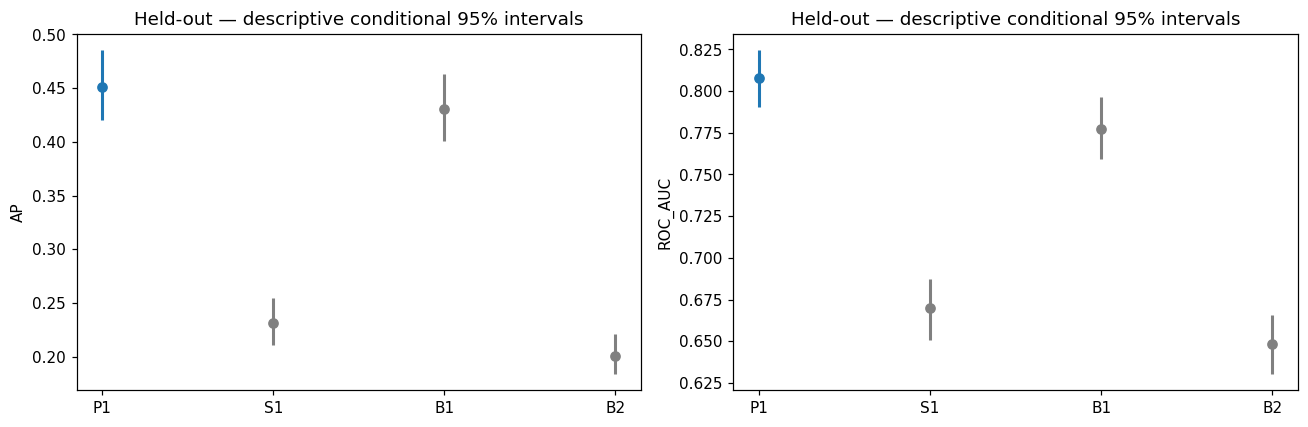

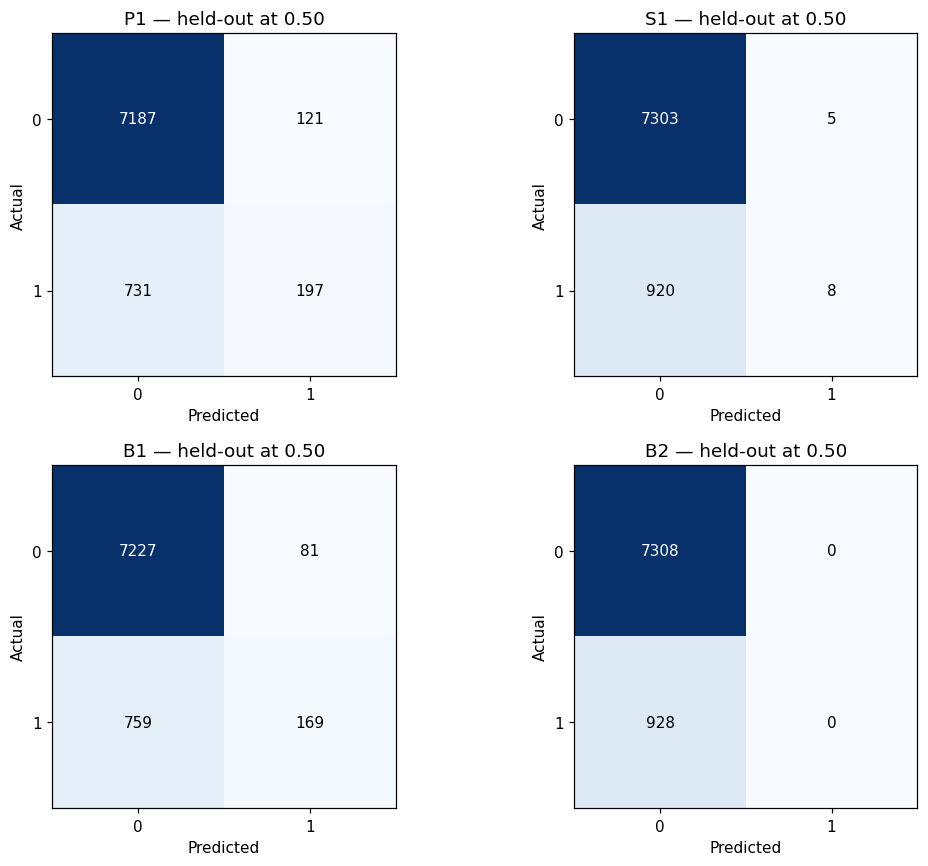

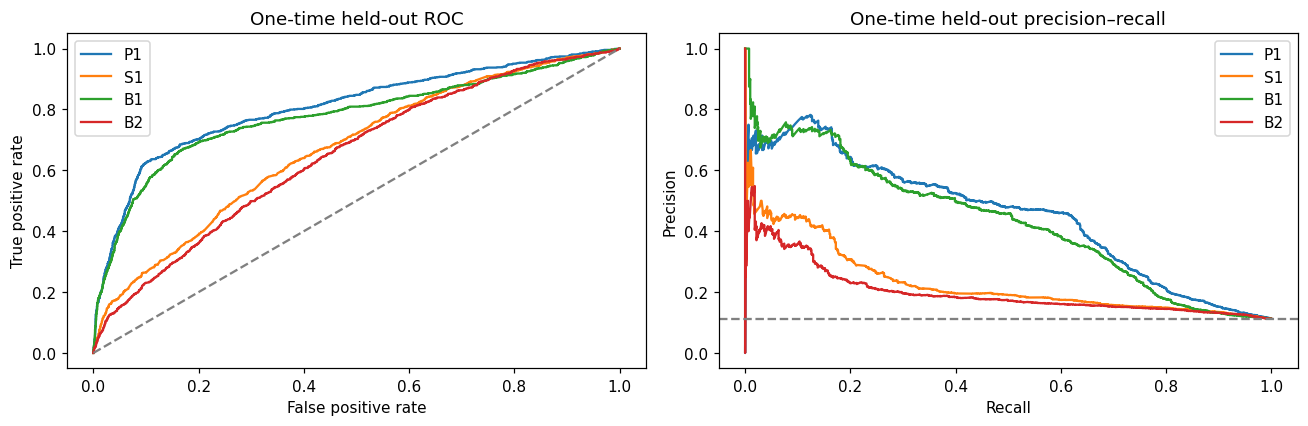

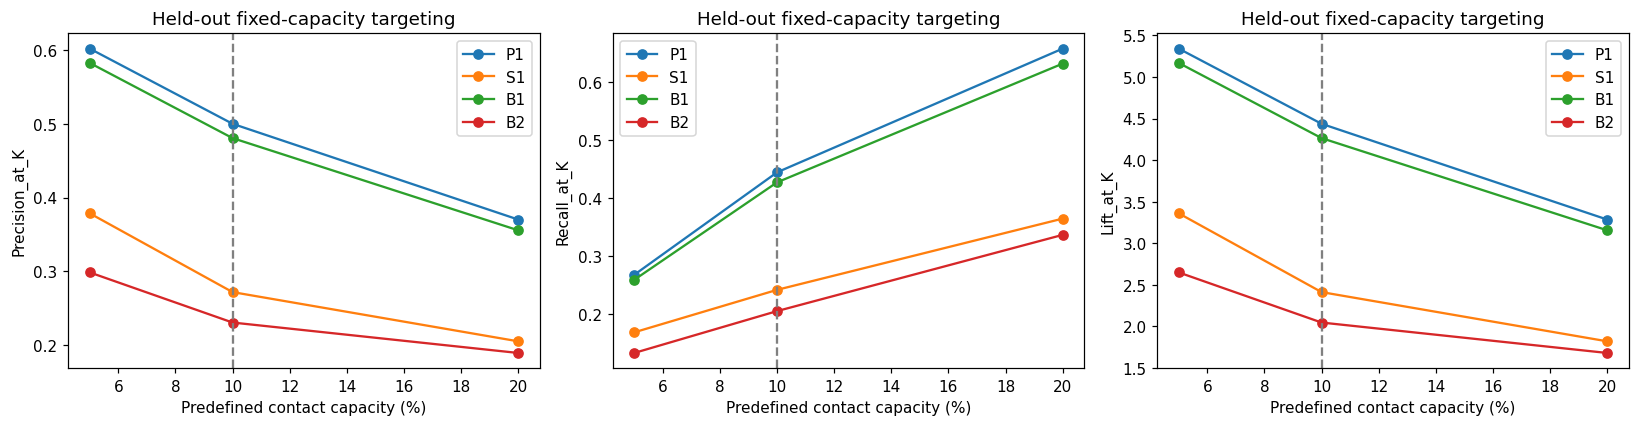

In [7]:
prior=(PROJECT_DIR/'09_feature_ablation_summary.md').read_text()
lines=[]
for line in prior.split('## Mean and sample SD of outer metrics',1)[1].splitlines():
    if line.startswith('| '):lines.append(line)
    elif lines:break
cols=[v.strip() for v in lines[0].split('|')[1:-1]]
prior_frame=pd.DataFrame([[v.strip() for v in l.split('|')[1:-1]] for l in lines[2:]],columns=cols)
comparison_rows=[]
for sid,spec in SCENARIOS.items():
    row=prior_frame.loc[prior_frame.model.eq(spec['model'])&prior_frame.feature_group.eq(spec['group'])].iloc[0]
    test_row=point.loc[point.scenario.eq(sid)].iloc[0]
    dev_ap=float(row['AP mean ± SD'].split(' ± ')[0]);dev_auc=float(row['ROC_AUC mean ± SD'].split(' ± ')[0])
    comparison_rows.append({'scenario':sid,'role':spec['role'],'prior_nested_AP_mean_SD':row['AP mean ± SD'],
        'heldout_AP':test_row.AP,'AP_test_minus_prior_nested_mean':test_row.AP-dev_ap,
        'prior_nested_ROC_AUC_mean_SD':row['ROC_AUC mean ± SD'],'heldout_ROC_AUC':test_row.ROC_AUC,
        'ROC_AUC_test_minus_prior_nested_mean':test_row.ROC_AUC-dev_auc})
comparison=pd.DataFrame(comparison_rows)
display(comparison)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['AP','ROC_AUC']):
    d=intervals.loc[intervals.metric.eq(metric)].set_index('scenario').loc[list(SCENARIOS)]
    for i,(sid,row) in enumerate(d.iterrows()):
        ax.vlines(i,row.lower_95,row.upper_95,color='tab:blue' if sid=='P1' else 'gray',lw=2)
        ax.scatter(i,row.estimate,color='tab:blue' if sid=='P1' else 'gray')
    ax.set_xticks(range(4),list(SCENARIOS));ax.set(ylabel=metric,title='Held-out — descriptive conditional 95% intervals')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,(sid,spec) in zip(axes.ravel(),SCENARIOS.items()):
    row=point.loc[point.scenario.eq(sid)].iloc[0];cm=np.array([[row.TN,row.FP],[row.FN,row.TP]],dtype=int)
    ax.imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicted',ylabel='Actual',title=sid+' — held-out at 0.50')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for sid in SCENARIOS:
    p=frozen_predictions[sid].to_numpy();fpr,tpr,_=roc_curve(actual,p);prec,rec,_=precision_recall_curve(actual,p)
    axes[0].plot(fpr,tpr,label=sid);axes[1].plot(rec,prec,label=sid)
axes[0].plot([0,1],[0,1],ls='--',color='gray');axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='One-time held-out ROC')
axes[1].axhline(actual.mean(),ls='--',color='gray');axes[1].set(xlabel='Recall',ylabel='Precision',title='One-time held-out precision–recall')
for ax in axes:ax.legend()
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['Precision_at_K','Recall_at_K','Lift_at_K']):
    for sid in SCENARIOS:
        d=business.loc[business.scenario.eq(sid)];ax.plot(d.fraction*100,d[metric],marker='o',label=sid)
    ax.axvline(10,ls='--',color='gray');ax.set(xlabel='Predefined contact capacity (%)',ylabel=metric,title='Held-out fixed-capacity targeting');ax.legend()
plt.tight_layout();plt.show()



## 8. Final technical, statistical and business report

Recheck immutable source/model/gate hashes; keep P1 sole primary. Summarize selected configurations, release timing, one-time exposure, metrics/uncertainty, historical subscriber capture, prior nested comparisons and limitations. Full and customer-only remain Provisional. No causal ROI, verified campaign-start eligibility, new post-test experiments, commit or push. The test partition is now exposed for this authorized final batch and cannot be recycled for further model selection.


In [8]:
for n,h in source_hashes.items():assert sha(PROJECT_DIR/n)==h
assert sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')==release['gate_document_sha256']
for sid,meta in manifest['scenarios'].items():assert sha(PROJECT_DIR/meta['artifact'])==meta['artifact_sha256']
assert list(point.scenario)==['P1','S1','B1','B2'] and done['primary_scenario']=='P1'
assert np.isfinite(point.select_dtypes('number').to_numpy()).all() and np.isfinite(business.select_dtypes('number').to_numpy()).all()
assert len(intervals)==108 and len(boot)==8000
# Frozen results/metadata are never overwritten by replay; only presentation is regenerated.
selection=pd.read_csv(RESULTS_DIR/'final_selected_parameters.csv',float_precision='round_trip')
primary10=business.loc[business.fraction.eq(.1)].copy()
other=business.loc[~business.fraction.eq(.1)].copy()
score_by_id=point.set_index('scenario');b_by=business.set_index(['scenario','fraction'])
rank_order=point.sort_values('AP',ascending=False).scenario.tolist()
contrast=[]
for left,right,label in [('P1','S1','HGB Full minus Customer Only'),('B1','B2','LR Full minus Customer Only'),('P1','B1','Full HGB minus Full LR'),('S1','B2','Customer HGB minus Customer LR')]:
    contrast.append({'comparison':label,'AP_difference':float(score_by_id.loc[left,'AP']-score_by_id.loc[right,'AP']),
        'ROC_AUC_difference':float(score_by_id.loc[left,'ROC_AUC']-score_by_id.loc[right,'ROC_AUC']),
        'Top10_capture_difference':int(b_by.loc[(left,.1),'captured_subscribers']-b_by.loc[(right,.1),'captured_subscribers'])})
contrast=pd.DataFrame(contrast)
selected_intervals=intervals.loc[intervals.metric.isin(['AP','ROC_AUC','Top10_captured_subscribers','Top10_Precision_at_K','Top10_Recall_at_K','Top10_Lift_at_K'])]
params_text='\n'.join('- '+sid+': `'+json.dumps(manifest['scenarios'][sid]['selected_parameters'],sort_keys=True)+'`.' for sid in SCENARIOS)
p1=score_by_id.loc['P1'];p1k=b_by.loc[('P1',.1)]
summary=f"""# Phase 7 — Final training, freeze and one-time held-out evaluation

## Completion and fixed primary scenario

Executed from approved merged main **{SOURCE_MAIN}**. The user's Phase 7 instruction explicitly approves the Phase 6B four-scenario historical academic protocol, both stages and automatic continuation after a passing gate. Earlier Phase 6B documents retain their original proposed wording unchanged; this new authorization is recorded in models/phase7_protocol.json, the manifest and event log. No material protocol conflict was found.

**P1 remains the sole primary**: original HGB, Full 15 Provisional predictors. S1 is customer-only HGB sensitivity; B1 full LR and B2 customer-only LR are secondary benchmarks. All 15 predictors remain Provisional. These are conditional historical academic results, not verified deployment readiness. No scenario, model, feature set, threshold or capacity was chosen from test performance.

All required Phase 7 outputs are present: executed notebook, this report, preserved pre-test PASS gate, four frozen complete sklearn Pipelines plus manifest/protocol, frozen predictions, point metrics, targeting tables, 2,000 paired stratified metric-bootstrap replicates/intervals and reproducibility/audit metadata. No prior Phase 2C–6B artifact was overwritten. No commit, push, merge or next experiment occurred.

## Final development-only selection and training

{params_text}

{mdtable(selection)}

Each scenario independently searched the exact approved grid with StratifiedKFold(5, shuffle=True, random_state=42), positive-class predict_proba AP scorer, refit='AP', n_jobs=1, error_score='raise'. HGB grid 16 candidates; LR C grid 3. Highest unrounded mean AP wins; exact ties use first ParameterGrid order. Detailed 38 candidates × five folds are in results/development_cv_candidates.csv. **190 candidate-fold fits +4 permitted all-development winner refits =194 model fits**; all input rows are saved development records. CV selection AP above is a tuning estimate, not independent test performance. Training/search/freezing time: {manifest['training_seconds']:.2f}s, including audits; not a controlled hardware benchmark.

Full uses exact original FEATURES order; customer-only uses age, job, marital, education, default, housing, loan. The exact approved Phase 6A subset adapter was extracted as a single function from its digest-verified notebook, not reimplemented or its modeling cells rerun. Full adapter output/statistics match the original approved factory on development-only fixtures. Customer-only removes excluded columns and the recency component entirely. No constant stand-ins or new features.

HGB: unscaled approved tree preprocessing, numeric full one-hot, categorical_features=None, early_stopping=False, class_weight=None, seed42. LR: approved training-only StandardScaler and observed-only ConditionalRecencyScaler when Full, lbfgs, max_iter1000, default L2, class_weight=None, seed42. sklearn 1.8 represents default L2 with l1_ratio=0 and a deprecated penalty sentinel; leaving the approved default unchanged avoids an unnecessary deprecation warning. No calibration, learned threshold, sampling or class weighting.

Serialized artifacts are plain complete sklearn Pipelines containing the already-fitted approved preprocessing and classifier; the experiment-only audit wrapper is omitted without refitting or changing learned steps. Four trusted locally created artifacts reloaded with **bit-identical probabilities on 256 development-only fixture records** before release. No untrusted pickle was loaded. Joblib artifacts require a compatible trusted environment and preprocessing.py.

## Release gate before test access

**PASS — All requirements satisfied.** [12_pre_holdout_release_gate.md](12_pre_holdout_release_gate.md) was written at {release['saved_at_utc']} UTC before any test parser invocation. Gate document SHA-256 `{release['gate_document_sha256']}` is preserved unchanged. models/model_manifest.json SHA-256 `{release['manifest_sha256']}` and protocol/code digests were recorded before exposure. results/phase7_events.jsonl and test_access_started.json record the ordered events.

Training isolation checked every candidate/refit row set, fold-specific category levels, selected numerical means/population variances/scales and available-only recency statistics. Unavailable transformed recency days remain zero; availability stays unscaled; original 999 never enters numeric recency. Customer-only has no recency transformer. Validation transforms did not change fitted signatures; finite outputs and [0,1] class mapping passed. Full adapter equivalence, synthetic targeting/tie/metric checks and **four existing preprocessing tests passed**. No unexpected training or prediction warnings occurred. Original datasets, saved indices and preprocessing.py retain approved digests.

Gate passage continued automatically under existing authorization. The exact saved **8,236** test observations were parsed once, restored to saved ordered cleaned-row positions and never dropped, rebalanced, relabelled or used for fitting. **Exactly one predict_proba call per scenario** generated all four vectors before any test metric was calculated. No test fit/fit_transform, vocabulary update, scaling update, threshold fitting or calibration occurred. Immutable predictions are in results/heldout_predictions.csv, with row positions, y and four positive-class probability columns. The test partition is now evaluated/exposed, not available for new model selection.

## Held-out predictive and .50 reference results

Observed prevalence: **{actual.mean():.6f}** ({int(actual.sum())} subscribers / {len(actual)} records). This is post-release evaluation context only, not a selection input. Positive class is 1; classification uses probability>=.50, zero_division=0. AP is sklearn Average Precision, not trapezoidal PR area; ROC-AUC uses the same positive probabilities.

{mdtable(point)}

Confusion matrices follow **[[TN, FP], [FN, TP]]**, actual rows [0,1], predicted columns [0,1]; corresponding counts are above and in results/heldout_metrics.csv. P1 AP={p1.AP:.6f}, ROC-AUC={p1.ROC_AUC:.6f}. Observed descending held-out AP order is {', '.join(rank_order)}. This descriptive ordering does not change P1's sole-primary status or select a deployment model.

AP is prioritized because subscribers are the minority and positive ranking quality matters; a mostly-negative classifier can have high accuracy. The .50 rule is a reference, not a calibrated, cost-optimal or capacity-preserving decision. Threshold changes alone can change precision/recall/F1/contact volume but cannot change AP/ROC-AUC for fixed scores. No alternative cutoff was selected here.

## Primary illustrative business capacity — top 10%

**824 contacts for every scenario**, fixed before test access; not a bank-confirmed operational budget.

{mdtable(primary10)}

P1 identifies **{int(p1k.captured_subscribers)} historical subscribers**, conversion concentration/Precision@824={p1k.Precision_at_K:.6f}, Recall@824={p1k.Recall_at_K:.6f}, Lift@824={p1k.Lift_at_K:.6f}. These counts describe historical subscriber identification, not subscribers caused by calls or guaranteed future conversions.

## Predefined secondary capacities — top 5% and 20%

{mdtable(other)}

Contact counts are exactly 412 / 824 / 1,648. Rank descending score, ties ascending immutable cleaned-row position, independent of outcome. Precision@K=captured/K; Recall@K=captured/total positives; Lift@K=Precision@K/prevalence. Same K across scenarios. Broader capacity trades contact volume for subscriber coverage; use actual results rather than infer a financially optimal budget. No call costs, incremental value, experimental treatment effect or ROI is known.

## Feature and model contrasts — descriptive, no test-driven reselection

{mdtable(contrast)}

The Full-versus-Customer contrasts quantify this frozen pair of models on this cohort, including their development-selected configurations. They do not isolate causal effects of economic/history variables or establish remaining feature timing. The HGB-versus-LR contrasts show whether the historical ranking advantage persists here, without a statistical-significance/winner claim. Do not add the untested No Economic/No History subsets or new models to explain a surprising result.

Prior Phase 5B-2 balanced HGB offered only small, capacity-dependent gains (+13/-18/-6 historical subscribers at development 5/10/20%) and a 0.002738 mean AP increase. RandomUnderSampler reduced HGB AP and capture. Original threshold-only F1 strategies already changed recall substantially. Therefore the pre-test plan retained original unweighted models, not an assumption that imbalance treatments never help. No treatment was reconsidered after test results.

## Comparison with previous nested development CV

{mdtable(comparison)}

Prior full-feature values come from Phase 5A and its Phase 6A replication; customer-only values from Phase 6A's own nested searches. Differences are test point estimates minus prior five-fold means. Read them as apparent generalization differences across partitions/training procedures, not a paired test, confidence bound or proof of distributional stability. Final models were selected/refitted on all development whereas nested models fit less data per outer fold. Prior CV SD is descriptive fold spread; it is not a test CI. Full-development best-CV selection scores are separately labelled above and are not substituted for this comparison.

## Bootstrap uncertainty

Exactly **2,000 stratified paired metric-bootstrap replicates**, NumPy default_rng(42)/PCG64. Draw with replacement within each observed class, preserving original counts; use the identical draws for all four frozen scenarios. No model fitting, prediction, transform, recalibration or threshold fitting in bootstrap. Recompute .50 metrics and Top-K using cohort length/ceil capacity and deterministic ties: score, original row position, duplicate draw-occurrence position. Original outcomes do not break ties. Draw digests and 8,000 scenario-replicate rows are saved.

Selected AP/ROC and primary-capacity intervals:

{mdtable(selected_intervals)}

All predefined metric intervals (2.5th/97.5th percentiles, NumPy linear quantiles):

{mdtable(intervals)}

These are **descriptive 95% intervals conditional on the fitted models and observed class balance**. They omit uncertainty from prior development-driven family/feature/grid selection, fitting variation, unknown customer clustering, temporal overlap, source timing, prevalence change and future deployment shift. Row-wise resampling may be optimistic with repeated customers/shared periods. No significance test or multiplicity-free inference is claimed; intervals and secondary scenarios do not reselect the primary model. They are not guaranteed future ranges and do not establish causal campaign uplift.

## Reproducibility and frozen artifacts

- 11_final_training_and_test.ipynb includes development fitting/freezing, gate, one-time evaluation, bootstrap and four figures. **Default replay mode** reads digest-verified frozen prediction/results files, recomputes deterministic point tables/figures and loads saved bootstrap intervals/replicates; it does not refit, predict from models or reopen raw held-out records. Initial mode refuses existing freeze/gate/access artifacts.
- models/P1_pipeline.joblib, S1_pipeline.joblib, B1_pipeline.joblib, B2_pipeline.joblib: trusted frozen complete pipelines. model_manifest.json records exact parameters, preprocessing signatures, schemas/classes, versions/seeds/source/model hashes; phase7_protocol.json records the pre-test rules/approval and execution-code hash.
- results/: development candidates/audits/tests; final parameters; immutable heldout_predictions.csv; heldout_metrics.csv and heldout_topk.csv; bootstrap_intervals.csv, bootstrap_replicate_metrics.csv.gz, bootstrap_draw_digests.csv and metadata; release-gate/access/prediction audits; event log and evaluation_complete.json containing frozen file digests and counts.
- Source cleaned SHA-256 `{source_hashes['02_cleaned_dataset.csv']}`; split SHA-256 `{source_hashes['03_split_indices.json']}`; preprocessing SHA-256 `{source_hashes['preprocessing.py']}`. Complete raw/source/plan hashes are in the manifest. No saved split or previous notebook/data/module was changed.
- Versions: {json.dumps(VERSIONS,sort_keys=True)}. GridSearch/native threads bounded to one. Hosted Colab was not directly exercised; portable repository/Drive loading and pinned tested versions are documented. Execution code digest excludes notebook outputs so saving results does not alter frozen algorithm identity.

## Research limitations and final implications

All 15 predictors remain Provisional, including customer-only fields. Campaign-start snapshots, previous-campaign cutoff, recency reference date, economic release/revision vintages and the outcome window remain unverified. Strong Full performance cannot make those fields deployable. This is conditional historical prediction in the provided marketing cohort, not verified prospective pre-campaign targeting, causal uplift or financial impact.

Missing customer IDs and campaign dates prevent grouped-customer and forward-time validation and can permit repeated-client or temporal overlap across the saved random split. Prior whole-dataset EDA and development-based model/grid/shortlist selection limit any pristine-holdout claim, even though no held-out predictive fitting/tuning occurred. All scenario roles/policies were fixed before exposure; the holdout has now been used once for its authorized batch and must not become a new development set for repeated experimentation.

Use these results to document the frozen academic comparison and its business-capacity trade-offs. Deployment would require verified time-aligned inputs/labels, customer/time validation, real operational objectives/costs and prospective evidence in a separately authorized study. Do not change models, add experiments or choose another primary based on these results. **Stop after Phase 7; no commit or push pending review.**
"""
(PROJECT_DIR/'11_final_training_and_test_summary.md').write_text(summary)
print('All Phase 7 deliverables saved. P1 remains sole primary; models/gate/predictions unchanged; no new experiments or commit/push.')


All Phase 7 deliverables saved. P1 remains sole primary; models/gate/predictions unchanged; no new experiments or commit/push.


## Final independent verification

All 14 release-gate checks and gate-before-parser chronology verified. Independently recomputed all four held-out metric records, 12 Top-K rows, 108 percentile intervals and 2,000 paired draw digests from frozen predictions/replicates. The 194 fitting records, four trusted reload checks, fixed code hash and all prior tracked bytes match. Safe replay of all eight code cells passed with model fitting/prediction/transformation, joblib loading and raw CSV parsing blocked; published summary was byte-identical. No new model fitting or raw held-out access was used in this verification. See results/final_validation.json. P1 remains sole primary; all features remain Provisional. No commit/push or further experiments.
